# Comprehensive Flagging Tutorial

_The previous tutorial (tutorial 2) discussed bitmasks and how to manipulate flag bitmasks we developed for M3. Here we will cover what each flag means for data quality. We will also generate a flag file for an existing L1B observation._

In [1]:
import numpy as np                # for scientific computing, good for working with large arrays  
import pandas as pd               # for data analysis, has easy to work with data frames 
import matplotlib.pyplot as plt   # for plotting 
from astropy.io import fits       # for reading / writing / manipulating FITS files 

import sys
sys.path.append('../') 

# FLAG DEFINITIONS 
NO_FLAG = 0
L2_DEPRECATED = 1 # bit 0, bands flagged by the mission in L2 as deprecated
NAN = 2           # bit 1, pixels set to NaN for being negative at L0 level
BDE = 4           # bit 2, pixels spectrally interpolated bc of the BDE
BAD_COL = 8       # bit 3, pixels part of a column offset from its neighbors
# FLAGS FOR FLICKER FLAGGING
NO_FLICKER = 16   # bit 4, bad-group column, no flicker on this line
FLICKER_BUMP = 32 # bit 5, flickers brighter than neighbors
FLICKER_DROP = 64 # bit 6, flickers darker than neighbors
# FLAGS REMAINING:  128 / bit 7

## Flag Meanings 

As a refresher, the flag values are as follows: 

| Flag          | Value | Binary      | Bit position | Meaning                                              |
|---------------|-------|-------------|--------------|------------------------------------------------------|
| NO_FLAG       | 0     | `00000000`  |             | No flag set                                          |
| L2_DEPRECATED | 1     | `00000001`  | bit 0        | Band flagged by the mission in L2 as deprecated      |
| NAN           | 2     | `00000010`  | bit 1        | Pixel set to NaN for being negative at L0 level      |
| BDE           | 4     | `00000100`  | bit 2        | Column spectrally interpolated because of the BDE     |
| BAD_COL       | 8     | `00001000`  | bit 3        | Column offset from its neighbors  |
| NO_FLICKER    | 16    | `00010000`  | bit 4        | Bad-group column, no flicker on this line            |
| FLICKER_BUMP  | 32    | `00100000`  | bit 5        | Flickers brighter than neighbors                     |
| FLICKER_DROP  | 64    | `01000000`  | bit 6        | Flickers darker than neighbors                       |

### Flag 1: L2 Deprecated 
Between L1B (radiance) and L2 (reflectance), the mission deprecated a selection of bands. These bands were processed to L1B but all of their values were set to -999 in L2. All pixels in these deprecated bands are flagged with `flag 1`. 

* For target mode these bands were: [0, 1, 2, 3, 4, 5, 6, 7, 255]. 

* For global mode these bands were: [0, 1] 

_This means, for global mode, a deprecated band in target mode is averaged into band 85 and not flagged._ 

### Flag 2: Negative L0 Values / NAN

L0 raw observational data (DN) was stored as a 12 bit unsigned integer on the spacecraft but saved as a 16-bit signed integer in the PDS. 
This means the maximum value observed in L0 data is 4095. Such high values are typically only observed in target mode, which was not as downsampled as global mode, where the largest values are around 3000. 

There appears to have been a rollover effect, where, when values surpassed 4095, they became 0 in target mode and 0, -1, or -2 in global mode. The dark signal background of normal observational data not experiencing this rollover effect is typically at least 300 DN. Therefore we set 0 and negative values in the L0 observational data as NAN in the pipeline and flag it with `flag 2`. 

This rollover effect was covered for the dark signal observations with the flag 1.5 in the mission-produced BDE maps. 

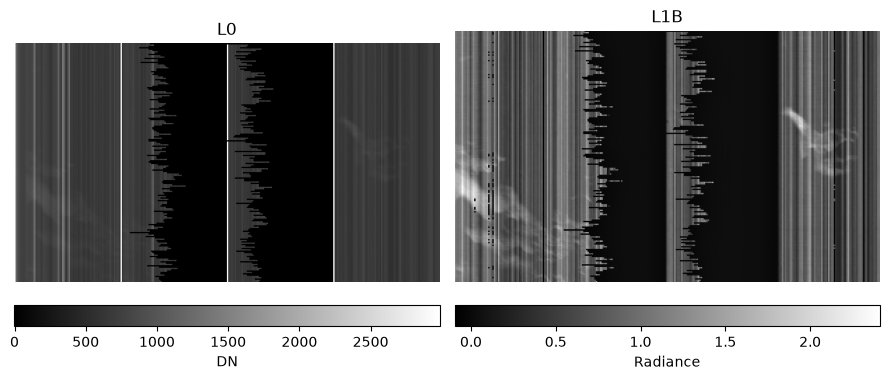

In [2]:
# load l0 and l1b data 
path_to_negative_l0 = "./tutorial_data/l0_m3g20081118t222604_b83.fits"   # for file size purposes I saved only one band of this obs
with fits.open(path_to_negative_l0) as hdul:
    l0 = hdul[0].data
    
path_to_negative_l1b = "./tutorial_data/l1b_m3g20081118t222604_b82.fits" # band index for l1b global mode is offset from l0 by one
with fits.open(path_to_negative_l1b) as hdul:
    l1b = hdul[0].data

# choose section of the band to view 
l0_section = l0[1000:1180, :]
l1b_section = l1b[1000:1180, :]

# show both images with colorbars 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 6))
im1 = ax1.imshow(l0_section, cmap="gray")
ax1.set_title("L0")
fig.colorbar(im1, ax=ax1, orientation="horizontal", pad=0.04, label="DN")
ax1.axis('off')
im2 = ax2.imshow(l1b_section, cmap="gray")
ax2.set_title("L1B")
fig.colorbar(im2, ax=ax2, orientation="horizontal", pad=0.04, label="Radiance")
ax2.axis('off')
plt.tight_layout()
plt.show()

Above is an example global-mode L0 observation (left) with negative pixels at band 83. These negative values were converted to radiance in the L1B product on the right. The pattern of these rollovers usually looks like a sideways histogram, as above. 

We think these rollover values are usually a result of high detector temperatures above ~165 K. 

### Flag 4: Bad Detector Elements (BDE) 

The original mission files have flag backplanes they call bad detector element maps (BDE) that are generated from dark signal observations. These files have the same orientation and number of bands & samples as the L0 data, but not the L1B data. They are provided in the USGS PDS as files ending in '_bde.fits'. These BDE maps are in detector POV, where the x-axis is samples (cross-track) and y-axis bands / channels. 

__As part of calibration, flagged pixels in the BDE maps were linearly spectrally interpolated. This means values at the interpolated pixels are not true observational data.__

Here is an example BDE map from the mission. 

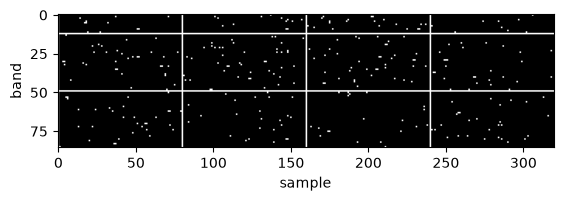

In [3]:
bde_id = 'm3g20090420t201515'
path_to_bde = f"./tutorial_data/{bde_id}_bde.fits"
with fits.open(path_to_bde) as hdul: 
    mission_bde = hdul[0].data

# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(mission_bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

The mission-derived BDE maps have the same number of bands and samples / columns as the L0 data. To flag L1B data as spectrally interpolated by the mission, we use the orientation information from the label files to reverse the lines and/or samples, if indicated. 
We also trim the bands and samples to match the L1B data. 

`Flag 4` is applied for all lines of a pixel flagged in the BDE map. This means every `flag 4` pixel in a band was interpolated across with the closest unflagged bands, and is not a real measurement. The number of pixels flagged in a BDE map is highly correlated with 
observation temperature. Warmer observations are therefore more heavily flagged. 

#### Remaking the BDE Maps 

The specific thresholds and method for making the BDE maps were not disclosed by the mission. However, we know they used the dark signal observation standard deviation and mean values. 

You can recreate their BDE maps using our function below, if you so desire. They are very close to the same, although not perfect. For flagging pre-existing L1B data, we recommend you download the BDE map produced by the mission from the PDS. 

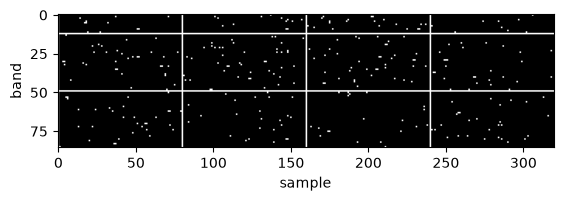

In [4]:
from m3_pipeline_tools.flagging.primary_flagging import call_build_bde_mask

# observation ID is the date, time, and mode designation unique to every observation in the M3 corpus 
# in every file name in the PDS this is the part that goes before _l0.fits, _l2_rfl.fits etc 
obs_id = "m3g20090420t191718" 

# local root, where data is stored 
local_root = './tutorial_data'

# call build mask 
bde = call_build_bde_mask(obs_id=obs_id, local_root= local_root)

# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

### Flag 8: Bad Column Flag 

### Flags 16, 32, 64: Flicker Flags 

## Flagging Pre-Existing L1B Data

We can flag an already existing L1B data set with the BDE map, L0 data, and L1B data. This outputs only a flag backplane. 

To make a flag backplane from an existing L1B product you will need: 
1) the L1B observation data
You should have but aren't required:
2) the L0 observation data (if this isn't present we can't flag pixels that are negative in L0)
3) the BDE map ('bde_id') (if this isn't present we can't flag what was spectrally interpolated)

These files should all be stored in the local root you give the function. 

See the flagging tutorial (tutorial 2) for the flag meanings. 

In [ ]:
# import function for ONLY making flag map for L1B 
from m3_pipeline_tools.flagging.make_flag_backplanes import make_mission_l1b_flag_backplane

flag = make_mission_l1b_flag_backplane(
    obs_id = obs_id.lower(),
    local_root = local_root, 
    verbose=True,
)
    
fits.writeto(f'{local_root}/{obs_id}_flag.fits', flag, overwrite=True)
del flag